# planetx — Test Sheet

**Usage:** Kernel → Restart & Run All. Each cell covers one module; no check can stop the run.

Every check records status, message, hint, traceback, captured output and duration. Results are
written to `notebooks/test_output/results.json` after each check, so they survive a kernel crash.
The final cell prints the full report and writes `test_output/report.md`.

| Status | Meaning |
|---|---|
| `PASS`  | Check succeeded |
| `FAIL`  | Wrong result — an assertion failed; see message and hint |
| `ERROR` | Unexpected exception — see traceback |
| `TODO`  | Function still raises `NotImplementedError` |
| `SKIP`  | A prerequisite check did not pass, or live checks are disabled |

Sections 2–10 run offline against synthetic FITS cutouts and a mocked IRSA service, so they
verify logic rather than network access. Sections 11–12 query IRSA and SIMBAD; set
`RUN_LIVE = False` to skip them.

In [1]:
# ── 0 · Harness ───────────────────────────────────────────────────────────────
%load_ext autoreload
%autoreload 2
RUN_LIVE = True

import io, json, sys, tempfile, time, traceback, warnings
from contextlib import contextmanager, redirect_stdout, redirect_stderr
from datetime import datetime
from pathlib import Path

import numpy as np
import astropy.units as u
from astropy.coordinates import SkyCoord
from astropy.io import fits
from astropy.table import MaskedColumn, Table
from astropy.wcs import WCS

warnings.filterwarnings("ignore", category=fits.verify.VerifyWarning)
warnings.filterwarnings("ignore", message=".*httpx.*deprecated.*")

OUT = Path.cwd() / "test_output"
OUT.mkdir(exist_ok=True)
RESULTS_FILE = OUT / "results.json"
RESULTS: dict[str, dict] = {}
LABEL = {"pass": "PASS", "fail": "FAIL", "crash": "ERROR", "todo": "TODO", "skip": "SKIP"}
_SECTION = {"name": "setup", "needs": []}
TMP = Path(tempfile.mkdtemp(prefix="planetx_nb_"))
STARTED = datetime.now().isoformat(timespec="seconds")

def _save():
    RESULTS_FILE.write_text(json.dumps({"started": STARTED, "run_live": RUN_LIVE,
                                        "results": RESULTS}, indent=1, default=str))

def section(name, needs=()):
    """Start a section; every check in it depends on `needs` (e.g. its module's import)."""
    _SECTION.update(name=name, needs=list(needs))
    print(f"\n[{name}]")

def _record(name, status, msg="", tb="", out="", hint="", secs=0.0):
    RESULTS[name] = dict(section=_SECTION["name"], status=status, message=msg, hint=hint,
                         traceback=tb, output=out, seconds=round(secs, 3))
    _save()
    line = f"  {LABEL[status]:<5}  {name}" + (f"  —  {msg.splitlines()[0][:140]}" if msg else "")
    print(line)

def check(name, fn, hint="", needs=()):
    """Run one check. Never raises. Returns fn's value on pass, else None."""
    for dep in [*_SECTION["needs"], *needs]:
        if RESULTS.get(dep, {}).get("status") != "pass":
            _record(name, "skip", f"needs '{dep}' to pass first", hint=hint)
            return None
    buf, t0 = io.StringIO(), time.perf_counter()
    try:
        with redirect_stdout(buf), redirect_stderr(buf):
            value = fn()
        out = buf.getvalue()
        _record(name, "pass", out=out, secs=time.perf_counter() - t0)
        if out.strip():
            print("         " + out.strip().replace("\n", "\n         "))
        return value
    except NotImplementedError:
        _record(name, "todo", "not implemented yet", hint=hint, out=buf.getvalue(),
                secs=time.perf_counter() - t0)
    except AssertionError as e:
        _record(name, "fail", str(e) or "assertion failed (no message)", traceback.format_exc(),
                buf.getvalue(), hint, time.perf_counter() - t0)
    except Exception as e:
        _record(name, "crash", f"{type(e).__name__}: {e}", traceback.format_exc(),
                buf.getvalue(), hint, time.perf_counter() - t0)
    return None

def skip_all(names, reason):
    for n in names:
        _record(n, "skip", reason)

@contextmanager
def patched(obj, attr, value):
    """Temporarily replace obj.attr (a tiny monkeypatch)."""
    old = getattr(obj, attr)
    setattr(obj, attr, value)
    try:
        yield
    finally:
        setattr(obj, attr, old)

CENTER = SkyCoord(133.7951, -7.2451, unit="deg")

def fake_cutout(path, center, star, size=40, scale=6.15, rot_deg=30.0, zodi=5.0,
                flag_pixel=None, with_image_name=True):
    """SPHEREx-like MEF on a ROTATED TAN WCS with a Gaussian star at `star`.
    FLAGS uses the real SPHEREx convention: MSKNnnnn = name, MSKMnnnn = 1<<n."""
    w = WCS(naxis=2)
    w.wcs.ctype = ["RA---TAN", "DEC--TAN"]
    w.wcs.crval = [center.ra.deg, center.dec.deg]
    w.wcs.crpix = [size / 2 + 0.5, size / 2 + 0.5]
    s, th = scale / 3600, np.radians(rot_deg)
    w.wcs.cd = [[-s * np.cos(th), s * np.sin(th)], [s * np.sin(th), s * np.cos(th)]]
    x0, y0 = w.world_to_pixel(star)
    yy, xx = np.mgrid[:size, :size]
    img = zodi + 100 * np.exp(-((xx - x0) ** 2 + (yy - y0) ** 2) / (2 * 1.2 ** 2))
    flags = np.zeros((size, size), dtype=np.int32)
    if flag_pixel:
        flags[flag_pixel] = 1 << 4
    hdr = w.to_header(); hdr["BUNIT"] = "MJy/sr"
    fh = fits.Header({"MSKN0000": "TRANSIENT", "MSKM0000": 1, "MSKN0004": "HOT     ",
                      "MSKM0004": 16, "MSKN0021": "SOURCE  ", "MSKM0021": 1 << 21})
    hdus = [fits.PrimaryHDU(),
            fits.ImageHDU(img.astype(np.float32), hdr, name="IMAGE" if with_image_name else None)]
    if with_image_name:
        hdus += [fits.ImageHDU(flags, fh, name="FLAGS"),
                 fits.ImageHDU(np.full((size, size), zodi, np.float32), name="ZODI")]
    fits.HDUList(hdus).writeto(path, overwrite=True)
    return Path(path)

FITS_BYTES = (lambda p: p.read_bytes())(fake_cutout(TMP / "bytes.fits", CENTER, CENTER))
print(f"Harness ready.\n  results: {RESULTS_FILE}\n  scratch: {TMP}")

Harness ready.
  results: /mnt/data/projects/competitions/space-apps/2026/notebooks/test_output/results.json
  scratch: /tmp/planetx_nb__4jhetmr


In [2]:
# ── 1 · Imports ───────────────────────────────────────────────────────────────
section("imports")
import importlib
MODULES = {}
for _m in ["config", "targets", "query", "cutouts", "stack", "export", "pipeline", "cli", "api"]:
    def _imp(m=_m):
        MODULES[m] = importlib.import_module(f"planetx.{m}")
    check(f"import:{_m}", _imp, hint=f"syntax error or bad import in py/src/planetx/{_m}.py")
config, targets, query, cutouts, stack, export, pipeline, cli, api = (
    MODULES.get(m) for m in ["config", "targets", "query", "cutouts", "stack", "export", "pipeline", "cli", "api"])
Target = getattr(targets, "Target", None)


[imports]
  PASS   import:config
  PASS   import:targets
  PASS   import:query
  PASS   import:cutouts
  PASS   import:stack
  PASS   import:export
  PASS   import:pipeline
  PASS   import:cli
  PASS   import:api


In [3]:
# ── 2 · config.py ─────────────────────────────────────────────────────────────
section("config", needs=["import:config"])

def t_root():
    r = config.root()
    assert (r / "config" / "sources.toml").exists(), f"root() = {r} has no config/sources.toml"
check("config.root", t_root, "walk Path(__file__).parents until config/sources.toml exists")

def t_sources():
    s = config.load_sources()
    missing = [k for k in ("spherex", "grid", "cutout", "flags") if k not in s]
    assert not missing, f"sources.toml missing sections {missing}"
    assert "spherex_dr1" in s["spherex"]["collections"]
    assert "SOURCE" not in s["flags"]["bad"], "SOURCE marks real stars — never mask it"
check("config.load_sources", t_sources, "tomllib.loads(path.read_text())")

def t_targets_cfg():
    ids = [t["id"] for t in config.load_targets()]
    assert {"wise0855", "barnard", "eps-indi-b", "rw-aur", "r-dra"} <= set(ids), ids
check("config.load_targets", t_targets_cfg, "return the list under [[target]]")

def t_explicit():
    missing = [t["id"] for t in config.load_targets()
               if not all(k in t for k in ("ra", "dec", "pmra", "pmdec"))]
    assert not missing, (f"{missing} have no explicit ra/dec/pmra/pmdec — the build then depends "
                         "on SIMBAD being up")
check("config: curated targets are self-contained", t_explicit,
      "paste the SIMBAD values (J2000, mas/yr) into targets.toml with ref_epoch = 2000.0")

def t_dirs():
    c, w = config.cache_dir(), config.web_data_dir()
    assert c.is_dir() and c.name == "cache", c
    assert w.parts[-3:] == ("web", "public", "data"), w
check("config.cache_dir / web_data_dir", t_dirs)


[config]
  PASS   config.root
  PASS   config.load_sources
  PASS   config.load_targets
  PASS   config: curated targets are self-contained
  PASS   config.cache_dir / web_data_dir


In [4]:
# ── 3 · targets.py ────────────────────────────────────────────────────────────
section("targets", needs=["import:targets"])

def t_pm_dec():
    t = Target("x", "x", "", 10.0, 0.0, pmra=0.0, pmdec=10_000.0, ref_epoch=2000.0)
    got = t.at(2001.0).dec.arcsec
    assert abs(got - 10.0) < 1e-6, f"10 arcsec/yr north for 1 yr gave {got:.6f} arcsec"
check("Target.at (dec motion)", t_pm_dec, "dDec = pmdec * dt / 3.6e6 degrees")

def t_pm_ra():
    t = Target("x", "x", "", 10.0, 60.0, pmra=3600.0, ref_epoch=2000.0)   # 3.6"/yr on sky at dec 60
    dra = (t.at(2001.0).ra.deg - 10.0) * 3600
    assert abs(dra - 7.2) < 1e-3, f"RA coordinate moved {dra:.4f} arcsec, want 7.2 (= 3.6 / cos 60°)"
check("Target.at (RA ÷ cos dec)", t_pm_ra, "pmra already includes cos(dec): divide by it to get ΔRA")

def t_pm_back():
    t = Target("x", "x", "", 10.0, 0.0, pmdec=10_000.0, ref_epoch=2000.0)
    assert abs(t.at(1999.0).dec.arcsec + 10.0) < 1e-6, "going back in time must move the other way"
check("Target.at (negative dt)", t_pm_back)

def t_wrap():
    t = Target("x", "x", "", 359.9999, 0.0, pmra=3.6e6, ref_epoch=2000.0)   # +1 deg/yr
    ra = t.at(2001.0).ra.deg
    assert 0 <= ra < 1, f"RA {ra} not wrapped into [0, 360)"
check("Target.at (RA wrap)", t_wrap, "ra % 360")

def t_info():
    d = Target("a", "A", "k", 1.0, 2.0).info()
    need = {"id", "name", "kind", "ra", "dec", "pmra", "pmdec", "ref_epoch"}
    assert need <= set(d), f"missing {need - set(d)}"
    json.dumps(d, allow_nan=False)
check("Target.info", t_info)

def t_resolve_explicit():
    t = targets.resolve({"id": "w", "name": "W", "kind": "bd", "ra": 133.7951, "dec": -7.2451,
                         "pmra": -8000, "pmdec": 600})
    assert (t.ra, t.dec, t.pmra, t.pmdec, t.ref_epoch) == (133.7951, -7.2451, -8000, 600, 2000.0), t
check("targets.resolve (explicit values)", t_resolve_explicit, "must NOT call SIMBAD when ra/dec given")

def t_resolve_no_network():
    def boom(*a, **k): raise AssertionError("resolve() called SIMBAD even though ra/dec were given")
    with patched(targets, "from_simbad", boom):
        targets.resolve({"id": "w", "name": "W", "ra": 1.0, "dec": 2.0})
check("targets.resolve (no SIMBAD when explicit)", t_resolve_no_network)

def t_adhoc():
    t = targets.adhoc(133.7951, -7.2451)
    assert t.pmra == t.pmdec == 0, "custom positions have no proper motion"
    assert t.kind == "custom" and "133.7951" in t.id, t
check("targets.adhoc", t_adhoc)


[targets]
  PASS   Target.at (dec motion)
  PASS   Target.at (RA ÷ cos dec)
  PASS   Target.at (negative dt)
  PASS   Target.at (RA wrap)
  PASS   Target.info
  PASS   targets.resolve (explicit values)
  PASS   targets.resolve (no SIMBAD when explicit)
  PASS   targets.adhoc


In [5]:
# ── 4 · query.py ──────────────────────────────────────────────────────────────
section("query", needs=["import:query"])

def t_det():
    assert query.detector_of("SPHEREx-D3") == "D3", query.detector_of("SPHEREx-D3")
    assert query.detector_of("SPHEREx-D6") == "D6"
check("query.detector_of", t_det)

def t_empty():
    e = query.empty()
    missing = set(query.KEEP + ["detector"]) - set(e.colnames)
    assert len(e) == 0 and not missing, f"len={len(e)}, missing columns {missing}"
check("query.empty", t_empty)

def _sia_table(rows, extra=True):
    t = Table(rows=rows, names=["obs_id", "access_url", "energy_bandpassname", "t_min", "t_max",
                                "em_min", "em_max", "dataproduct_subtype", "obs_collection"])
    t["s_pixel_scale"] = MaskedColumn([6.15] * len(t), mask=[i == 0 for i in range(len(t))])
    if extra:
        t["s_region"] = ["POLYGON ..."] * len(t); t["cloud_access"] = ["{}"] * len(t)
    return t

FAKE_SIA = {
    "coll_a": _sia_table([
        ("o1", "u1", "SPHEREx-D1", 60800.7, 60800.8, 0.75e-6, 1.1e-6, "science", "coll_a"),
        ("o1", "u2", "SPHEREx-D4", 60800.7, 60800.8, 2.4e-6, 3.8e-6, "science", "coll_a"),
        ("o2", "u3", "SPHEREx-D2", 60990.0, 60990.1, 1.1e-6, 1.6e-6, "science", "coll_a"),
        ("c1", "u4", "SPHEREx-D2", 60990.0, 60990.1, 1.1e-6, 1.6e-6, "calibration", "coll_a")]),
    "coll_b": _sia_table([
        ("o2", "u3", "SPHEREx-D2", 60990.0, 60990.1, 1.1e-6, 1.6e-6, "science", "coll_b"),   # duplicate
        ("o3", "u5", "SPHEREx-D3", 61169.5, 61169.6, 1.6e-6, 2.4e-6, "science", "coll_b")], extra=False),
    "coll_empty": Table(),
}
def fake_query_sia(pos=None, collection=None, **kw):
    return FAKE_SIA.get(collection)

def t_find_offline():
    from astroquery.ipac.irsa import Irsa
    with patched(Irsa, "query_sia", fake_query_sia):
        t = query.find_images(CENTER, ["coll_a", "coll_b", "coll_empty", "coll_missing"])
    assert set(query.KEEP) <= set(t.colnames), f"missing columns {set(query.KEEP) - set(t.colnames)}"
    assert "s_region" not in t.colnames, "extra SIA columns should be dropped (only KEEP)"
    assert "detector" in t.colnames
    assert all(t["dataproduct_subtype"] == "science"), "calibration rows must be filtered out"
    pairs = sorted(zip(t["obs_id"], t["detector"]))
    assert pairs == [("o1", "D1"), ("o1", "D4"), ("o2", "D2"), ("o3", "D3")], f"got {pairs} (dedupe on obs_id+detector?)"
    return t
FOUND = check("query.find_images (fake IRSA: filter, merge, dedupe)", t_find_offline,
              "per collection: keep KEEP cols → plain str/float (masked → nan) → vstack → science only → "
              "detector col → unique(obs_id, detector). Empty / None collections must be skipped.")

def t_find_nothing():
    from astroquery.ipac.irsa import Irsa
    with patched(Irsa, "query_sia", lambda **k: Table()):
        t = query.find_images(CENTER, ["a", "b"])
    assert len(t) == 0 and "detector" in t.colnames, "nothing found → return query.empty()"
check("query.find_images (no data anywhere)", t_find_nothing)

EP = Table({"t_min": [61169.5, 60800.7, 60990.0, 60801.1, 60991.0],     # deliberately unsorted
            "t_max": [61169.6, 60800.8, 60990.1, 60801.2, 60991.1],
            "detector": ["D1", "D1", "D2", "D2", "D1"],
            "em_min": [0.75e-6, 0.76e-6, 1.1e-6, 1.12e-6, 0.8e-6],
            "em_max": [1.0e-6, 1.09e-6, 1.6e-6, 1.65e-6, 1.05e-6]})

def t_epochs():
    out = query.assign_epochs(EP, 30)
    assert list(out["t_min"]) == sorted(EP["t_min"]), "not sorted by t_min"
    assert list(out["epoch"]) == [0, 0, 1, 1, 2], f"epochs {list(out['epoch'])}, want [0,0,1,1,2]"
    assert "epoch" not in EP.colnames, "modified the input table — work on a copy"
    return out
EPO = check("query.assign_epochs", t_epochs, "sort, np.diff(t_min) > gap, cumsum")

def t_epochs_empty():
    out = query.assign_epochs(query.empty(), 30)
    assert len(out) == 0 and "epoch" in out.colnames
check("query.assign_epochs (empty)", t_epochs_empty, needs=["query.empty"])

def t_summary():
    s = query.epoch_summary(EPO)
    assert [x["id"] for x in s] == ["A", "B", "C"], [x.get("id") for x in s]
    assert s[0]["label"] == "May 2025", f"label {s[0]['label']!r}, want 'May 2025'"
    assert (s[0]["n_images"], s[0]["mjd_start"], s[0]["mjd_end"]) == (2, 60800.7, 60801.2), s[0]
    assert 2025.3 < s[0]["year_mid"] < 2025.4, s[0]["year_mid"]
    assert [x["index"] for x in s] == [0, 1, 2]
check("query.epoch_summary", t_summary, needs=["query.assign_epochs"])

def t_ranges():
    r = query.detector_ranges(EP)
    assert r == {"D1": [0.75, 1.09], "D2": [1.1, 1.65]}, f"{r} (µm = metres × 1e6, 3 dp)"
    assert all(type(k) is str for k in r), "keys must be plain str (np.str_ leaks into JSON keys)"
check("query.detector_ranges", t_ranges)


[query]
  PASS   query.detector_of
  PASS   query.empty
  PASS   query.find_images (fake IRSA: filter, merge, dedupe)
  PASS   query.find_images (no data anywhere)
  PASS   query.assign_epochs
  PASS   query.assign_epochs (empty)
  PASS   query.epoch_summary
  PASS   query.detector_ranges


In [6]:
# ── 5 · cutouts.py ────────────────────────────────────────────────────────────
section("cutouts", needs=["import:cutouts"])
import httpx

def t_url():
    u_ = cutouts.cutout_url("https://x/img.fits", CENTER, 0.05)
    assert u_ == "https://x/img.fits?center=133.795100,-7.245100&size=0.05000", u_
check("cutouts.cutout_url", t_url, "f'{url}?center={ra:.6f},{dec:.6f}&size={size:.5f}'")

def t_cache_key():
    a = cutouts.cutout_url("https://x/img.fits", CENTER, 0.05)
    b = cutouts.cutout_url("https://x/img.fits", SkyCoord(10, 10, unit="deg"), 0.05)
    c = cutouts.cutout_url("https://x/img.fits", CENTER, 0.06)
    pa, pb, pc = (cutouts.cache_path(x, TMP) for x in (a, b, c))
    assert len({pa, pb, pc}) == 3, "cache key must change with position AND size"
    assert pa == cutouts.cache_path(a, TMP), "cache key must be deterministic"
    assert pa.suffix == ".fits" and pa.parent == TMP
check("cutouts.cache_path", t_cache_key, "hash the FULL url (hashlib.sha1)")

def t_hit():
    url = "https://example.invalid/never-downloaded.fits"
    p = cutouts.cache_path(url, TMP); p.write_bytes(FITS_BYTES)
    assert cutouts.fetch_cutout(url, TMP) == p, "should return the cached file without downloading"
check("cutouts.fetch_cutout (cache hit)", t_hit)

def _client(responses):
    """httpx client whose server replies with the given (status, body) list, in order."""
    calls = {"n": 0}
    def handler(request):
        status, body = responses[min(calls["n"], len(responses) - 1)]
        calls["n"] += 1
        return httpx.Response(status, content=body)
    return httpx.Client(transport=httpx.MockTransport(handler)), calls

def t_download():
    c, calls = _client([(200, FITS_BYTES)])
    p = cutouts.fetch_cutout("https://mock/ok.fits", TMP, client=c)
    assert p.exists() and p.read_bytes() == FITS_BYTES and calls["n"] == 1
    assert not list(TMP.glob("*.part")), "leftover .part file — rename it into place"
check("cutouts.fetch_cutout (download + atomic write)", t_download)

def t_retry():
    c, calls = _client([(503, b"busy"), (503, b"busy"), (200, FITS_BYTES)])
    t0 = time.perf_counter()
    p = cutouts.fetch_cutout("https://mock/retry.fits", TMP, client=c)
    assert p.read_bytes() == FITS_BYTES, "did not end with the FITS body"
    assert calls["n"] == 3, f"made {calls['n']} requests, want 3 (2× 503, then 200)"
    print(f"retried in {time.perf_counter() - t0:.1f}s")
check("cutouts.fetch_cutout (retries 503)", t_retry,
      "IRSA rate-limits: on 503/429 sleep (1, 2, 4… s) and try again, up to `retries` times")

def t_not_fits():
    c, _ = _client([(200, b"<html>error page</html>")])
    try:
        cutouts.fetch_cutout("https://mock/html.fits", TMP, client=c)
    except ValueError:
        pass
    else:
        raise AssertionError("an HTML reply was saved as a .fits file")
    assert not cutouts.cache_path("https://mock/html.fits", TMP).exists(), "bad reply left in the cache"
check("cutouts.fetch_cutout (non-FITS → ValueError)", t_not_fits, "check body.startswith(b'SIMPLE')")

def t_404():
    c, calls = _client([(404, b"nope")])
    try:
        cutouts.fetch_cutout("https://mock/404.fits", TMP, client=c)
    except httpx.HTTPStatusError:
        pass
    else:
        raise AssertionError("404 did not raise")
    assert calls["n"] == 1, f"404 was retried {calls['n']} times — only retry 503/429"
check("cutouts.fetch_cutout (404 raises, no retry)", t_404)

def t_many():
    good = "https://example.invalid/never-downloaded.fits"
    bad = "https://example.invalid/does-not-exist.fits"
    seen = []
    out = cutouts.fetch_many([good, bad, good], TMP, workers=2, progress=lambda d, n: seen.append((d, n)))
    assert out[0] == out[2] == cutouts.cache_path(good, TMP) and out[1] is None, out
    assert len(seen) == 3 and max(d for d, _ in seen) == 3 and all(n == 3 for _, n in seen), seen
check("cutouts.fetch_many (order, failure → None, progress)", t_many)


[cutouts]
  PASS   cutouts.cutout_url
  PASS   cutouts.cache_path
  PASS   cutouts.fetch_cutout (cache hit)
  PASS   cutouts.fetch_cutout (download + atomic write)
  PASS   cutouts.fetch_cutout (retries 503)
         retried in 3.0s
  PASS   cutouts.fetch_cutout (non-FITS → ValueError)
  PASS   cutouts.fetch_cutout (404 raises, no retry)
  PASS   cutouts.fetch_many (order, failure → None, progress)
         cutout failed: https://example.invalid/does-not-exist.fits ([Errno -2] Name or service not known)


In [7]:
# ── 6 · stack.py ──────────────────────────────────────────────────────────────
section("stack", needs=["import:stack"])

def t_grid():
    g = stack.make_grid(CENTER, 25, 6.15)
    assert g.wcs.cdelt[0] < 0 < g.wcs.cdelt[1], "need east-left (CDELT1<0), north-up (CDELT2>0)"
    x, y = g.world_to_pixel(CENTER)
    assert abs(x - 12) < 1e-6 and abs(y - 12) < 1e-6, f"target at ({x:.3f},{y:.3f}), want (12,12) — CRPIX is 1-based"
    assert tuple(g.pixel_shape) == (25, 25)
    assert abs(abs(g.wcs.cdelt[0]) * 3600 - 6.15) < 1e-9, "pixel scale wrong (arcsec → deg)"
check("stack.make_grid", t_grid)

def t_flag_bits():
    h = fits.Header({"MSKN0004": "HOT     ", "MSKM0004": 16, "MSKD0004": "Hot pixel",
                     "MSKN0021": "SOURCE  ", "MSKM0021": 1 << 21, "OTHER": 1})
    assert stack.flag_bits(h) == {"HOT": 4, "SOURCE": 21}, stack.flag_bits(h)
check("stack.flag_bits", t_flag_bits, "MSKNnnnn = 'NAME' → {'NAME': n}; strip the padded name")

def t_bad_mask():
    h = fits.Header({"MSKN0004": "HOT", "MSKN0021": "SOURCE"})
    f = np.array([[0, 1 << 4], [1 << 21, (1 << 4) | (1 << 21)]])
    m = stack.bad_mask(f, h, ["HOT"])
    assert m.tolist() == [[False, True], [False, True]], m.tolist()
    assert not stack.bad_mask(f, fits.Header(), ["HOT"]).any(), "no MSKN keys → mask nothing"
    assert not stack.bad_mask(f, h, ["NOT_A_FLAG"]).any(), "unknown flag names must be ignored"
check("stack.bad_mask", t_bad_mask)

def t_load():
    p = fake_cutout(TMP / "load.fits", CENTER, CENTER, zodi=5.0, flag_pixel=(5, 5))
    data, wcs, meta = stack.load_cutout(p, bad_flags=["HOT"])
    assert np.isnan(data[5, 5]) and meta["masked"] == 1, meta
    assert abs(np.nanmedian(data)) < 1e-3, "ZODI not subtracted"
    assert wcs.naxis == 2 and meta["bunit"] == "MJy/sr", (wcs.naxis, meta)
    assert data.dtype.kind == "f" and data.dtype.itemsize == 8, f"cast to float64, got {data.dtype}"
    d2, _, _ = stack.load_cutout(p, bad_flags=None)
    assert np.isfinite(d2).all(), "bad_flags=None must not mask anything"
check("stack.load_cutout", t_load)

def t_load_fallback():
    p = fake_cutout(TMP / "noname.fits", CENTER, CENTER, with_image_name=False)
    data, wcs, meta = stack.load_cutout(p, bad_flags=["HOT"])
    assert data.shape == (40, 40)
check("stack.load_cutout (no IMAGE ext → HDU 1)", t_load_fallback)

def t_align():
    star = CENTER.spherical_offsets_by(3 * 6.15 * u.arcsec, -2 * 6.15 * u.arcsec)
    p = fake_cutout(TMP / "align.fits", CENTER, star)
    g = stack.make_grid(CENTER, 25, 6.15)
    img = stack.to_grid(p, g, 25)
    assert img.shape == (25, 25), img.shape
    r, c = np.unravel_index(np.nanargmax(img), img.shape)
    ex, ey = g.world_to_pixel(star)
    assert abs(c - ex) <= 1 and abs(r - ey) <= 1, f"peak at col {c}, row {r}; expected ~({float(ex):.1f}, {float(ey):.1f})"
    assert c < 12, "star is EAST — must be LEFT of centre"
    assert abs(np.nanmedian(img)) < 1e-6, "background (nanmedian) not subtracted"
check("stack.to_grid (alignment, rotated input)", t_align,
      "reproject_interp((data, wcs), grid, shape_out=(n, n)); check WCS is .celestial")

def t_offgrid():
    far = SkyCoord(134.5, -7.2451, unit="deg")
    p = fake_cutout(TMP / "far.fits", far, far)
    img = stack.to_grid(p, stack.make_grid(CENTER, 25, 6.15), 25)
    assert np.isnan(img).all(), "off-footprint pixels must be NaN, not 0"
check("stack.to_grid (off footprint → NaN)", t_offgrid, "out[footprint == 0] = np.nan")

def t_stack():
    a, b, c = np.ones((3, 3)), np.full((3, 3), 3.0), np.full((3, 3), np.nan)
    img, n = stack.stack_epoch([a, b, c, None])
    assert n == 2 and np.allclose(img, 2.0), (n, img)
    assert stack.stack_epoch([None, c]) == (None, 0)
    assert stack.stack_epoch([]) == (None, 0)
    p = np.ones((2, 2)); p[0, 0] = np.nan
    img, _ = stack.stack_epoch([p, p])
    assert np.isnan(img[0, 0]) and img[1, 1] == 1, "all-NaN pixel must stay NaN"
check("stack.stack_epoch", t_stack)


[stack]
  PASS   stack.make_grid
  PASS   stack.flag_bits
  PASS   stack.bad_mask
         FLAGS header has no MSKN* keys — no pixels masked
  PASS   stack.load_cutout
  PASS   stack.load_cutout (no IMAGE ext → HDU 1)
  PASS   stack.to_grid (alignment, rotated input)
  PASS   stack.to_grid (off footprint → NaN)
  PASS   stack.stack_epoch


In [8]:
# ── 7 · export.py ─────────────────────────────────────────────────────────────
section("export", needs=["import:export"])

def t_jsonable():
    out = export.to_jsonable(np.array([[1.0, 2.0], [3.0, np.nan]]))
    assert out == [[3.0, None], [1.0, 2.0]], f"row flip / NaN wrong: {out}"
    assert export.to_jsonable(np.array([[1.234567, np.inf, -np.inf]])) == [[1.235, None, None]]
    assert type(out[0][0]) is float, f"must be Python float, got {type(out[0][0])}"
    assert export.to_jsonable(np.full((2, 2), np.nan)) == [[None, None], [None, None]]
check("export.to_jsonable", t_jsonable, "np.flipud, then float(f'{v:.4g}') if finite else None")

def t_write():
    p = TMP / "sub" / "t.json"
    export.write_json(p, {"x": [[1.0, None]]})
    assert json.loads(p.read_text()) == {"x": [[1.0, None]]}
    try:
        export.write_json(p, {"bad": float("nan")})
    except ValueError:
        pass
    else:
        raise AssertionError("NaN was written — use json.dumps(..., allow_nan=False)")
    assert json.loads(p.read_text()) == {"x": [[1.0, None]]}, "a failed write clobbered the old file"
    assert not list(p.parent.glob("*.part")), "leftover .part file"
check("export.write_json", t_write)


[export]
  PASS   export.to_jsonable
  PASS   export.write_json


In [9]:
# ── 8 · pipeline.py (IRSA + downloads faked) ──────────────────────────────────
section("pipeline", needs=["import:pipeline", "import:query", "import:cutouts", "import:targets"])

SOURCES_T = {"spherex": {"collections": ["x"], "epoch_gap_days": 30, "obs_epoch": 2025.9,
                         "pixel_scale_arcsec": 6.15},
             "grid": {"size_px": 25}, "cutout": {"margin": 1.5, "workers": 2},
             "flags": {"bad": ["HOT"]}, "live": {"max_per_group": 4}}
PM = 2 * 6.15 * 1000 / 0.5            # +pmra = EAST, 2 px per half year
MOVER = Target("t", "Test", "test", CENTER.ra.deg, CENTER.dec.deg, pmra=PM, ref_epoch=2025.9) if Target else None
ROWS = Table({
    "obs_id": ["a", "b", "c", "d", "e", "f"], "access_url": ["u1", "u2", "u3", "u4", "u5", "u6"],
    "energy_bandpassname": ["SPHEREx-D1", "SPHEREx-D4", "SPHEREx-D1", "SPHEREx-D4", "SPHEREx-D1", "SPHEREx-D4"],
    "t_min": [60800.0, 60800.0, 61169.0, 61169.0, 61169.2, 61169.2],
    "t_max": [60800.1, 60800.1, 61169.1, 61169.1, 61169.3, 61169.3],
    "em_min": [0.75e-6, 2.4e-6] * 3, "em_max": [1.1e-6, 3.8e-6] * 3,
    "s_pixel_scale": [6.15] * 6, "dataproduct_subtype": ["science"] * 6,
    "obs_collection": ["spherex_dr1"] * 6, "detector": ["D1", "D4"] * 3})

def fake_fetch(urls, cache, workers=8, progress=None):
    out = []
    for u_ in urls:
        key = u_.split("?")[0]
        if key == "u6":                    # one download fails
            out.append(None); continue
        mjd = 60800.0 if key in ("u1", "u2") else 61169.0
        year = 2025.0 + (mjd - 60676.0) / 365.25
        p = TMP / f"pipe_{key}.fits"
        if not p.exists():
            fake_cutout(p, CENTER, MOVER.at(year))
        out.append(p)
    return out

def run_pipeline(rows=None, **kw):
    rows = ROWS if rows is None else rows
    with patched(query, "find_images", lambda *a, **k: rows.copy()), patched(cutouts, "fetch_many", fake_fetch):
        return pipeline.build_target(MOVER, SOURCES_T, TMP, **kw)

def t_pipe_shape():
    d = run_pipeline()
    json.dumps(d, allow_nan=False)
    missing = [k for k in ("target", "grid", "units", "generated_at", "collections", "detectors",
                           "epochs", "n_images", "n_used") if k not in d]
    assert not missing, f"missing top-level keys {missing}"
    assert d["n_images"] == 6, f"n_images {d['n_images']}, want 6"
    assert d["n_used"] == 5, f"n_used {d['n_used']}, want 5 (one download returned None)"
    assert [e["id"] for e in d["epochs"]] == ["A", "B"], [e.get("id") for e in d["epochs"]]
    e = d["epochs"][1]
    assert set(e["frames"]) == {"D1", "D4", "ALL"}, set(e["frames"])
    assert e["frames"]["D1"]["n_images"] == 2 and e["frames"]["D4"]["n_images"] == 1, \
        {k: v["n_images"] for k, v in e["frames"].items()}
    assert e["frames"]["ALL"]["n_images"] == 3
    px = e["frames"]["ALL"]["pixels"]
    assert len(px) == 25 and len(px[0]) == 25
    assert set(d["detectors"]) == {"D1", "D4"}
    assert {"x", "y"} == set(e["predicted_px"])
    return d
PIPE = check("pipeline.build_target (shape, counts, JSON-safe)", t_pipe_shape,
             "follow the 8 steps in the docstring; call query./cutouts. via the module so fakes apply")

def t_pipe_track():
    d = PIPE or run_pipeline()
    for e in d["epochs"]:
        img = np.array(e["frames"]["ALL"]["pixels"], dtype=float)
        r, c = np.unravel_index(np.nanargmax(img), img.shape)
        p = e["predicted_px"]
        assert abs(c - p["x"]) <= 1 and abs(r - p["y"]) <= 1, \
            f"{e['id']}: star at screen ({c},{r}) but predicted ({p['x']},{p['y']}) — y flipped?"
    a, b = d["epochs"][0]["predicted_px"], d["epochs"][1]["predicted_px"]
    assert b["x"] < a["x"], "moving EAST must move LEFT on screen"
check("pipeline.build_target (star on predicted_px)", t_pipe_track,
      "predicted y must be in SCREEN coords: size_px - 1 - y", needs=["pipeline.build_target (shape, counts, JSON-safe)"])

def t_pipe_cap():
    d = run_pipeline(max_per_group=1)
    n = d["epochs"][1]["frames"]["D1"]["n_images"]
    assert n == 1, f"max_per_group=1 but D1 stacked {n} images"
check("pipeline.build_target (max_per_group)", t_pipe_cap)

def t_pipe_dets():
    d = run_pipeline(detectors=["D4"])
    dets = {k for e in d["epochs"] for k in e["frames"]} - {"ALL"}
    assert dets == {"D4"}, f"detectors=['D4'] but frames for {dets}"
check("pipeline.build_target (detectors filter)", t_pipe_dets)

def t_pipe_empty():
    with patched(query, "find_images", lambda *a, **k: query.empty()):
        d = pipeline.build_target(MOVER, SOURCES_T, TMP)
    assert d["epochs"] == [] and d["n_images"] == 0 and d["detectors"] == {}, d
    json.dumps(d, allow_nan=False)
check("pipeline.build_target (no images)", t_pipe_empty)


[pipeline]
  PASS   pipeline.build_target (shape, counts, JSON-safe)
  PASS   pipeline.build_target (star on predicted_px)
  PASS   pipeline.build_target (max_per_group)
  PASS   pipeline.build_target (detectors filter)
  PASS   pipeline.build_target (no images)


In [10]:
# ── 9 · cli.py ────────────────────────────────────────────────────────────────
section("cli", needs=["import:cli", "import:config", "import:targets"])

def t_cli():
    out = TMP / "webdata"
    fake = lambda t, *a, **k: {"epochs": [{"id": "A"}], "n_images": 7, "n_used": 7}
    fake_resolve = lambda cfg: Target(cfg["id"], cfg["name"], cfg.get("kind", ""), 1.0, 2.0)
    with patched(config, "web_data_dir", lambda: out), \
         patched(cli, "build_target", fake), patched(cli.targets, "resolve", fake_resolve):
        cli.build(["wise0855"])
        cli.build(["barnard"])
    idx = json.loads((out / "targets.json").read_text())
    assert {e["id"] for e in idx} == {"wise0855", "barnard"}, f"index {[e['id'] for e in idx]} — must MERGE"
    entry = next(e for e in idx if e["id"] == "wise0855")
    assert entry["file"] == "targets/wise0855.json", entry
    assert json.loads((out / "targets" / "wise0855.json").read_text())["n_images"] == 7
    man = json.loads((out / "manifest.json").read_text())
    assert {"generated_at", "collections", "counts"} <= set(man), man
check("cli.build (writes + merges index)", t_cli)

def t_cli_failure():
    out = TMP / "webdata2"
    def flaky(t, *a, **k):
        if t.id == "barnard": raise RuntimeError("IRSA exploded")
        return {"epochs": [], "n_images": 0, "n_used": 0}
    fake_resolve = lambda cfg: Target(cfg["id"], cfg["name"], cfg.get("kind", ""), 1.0, 2.0)
    with patched(config, "web_data_dir", lambda: out), \
         patched(cli, "build_target", flaky), patched(cli.targets, "resolve", fake_resolve):
        cli.build(["wise0855", "barnard"])
    ids = {e["id"] for e in json.loads((out / "targets.json").read_text())}
    assert ids == {"wise0855"}, f"one failing target must not stop the others (got {ids})"
check("cli.build (one target fails, rest continue)", t_cli_failure)


[cli]
  PASS   cli.build (writes + merges index)
         ▶ wise0855 — WISE 0855-0714
           ✓ 1 epochs, 7 images
         ▶ barnard — Barnard's Star
           ✓ 1 epochs, 7 images
  PASS   cli.build (one target fails, rest continue)
         ▶ wise0855 — WISE 0855-0714
           ✓ 0 epochs, 0 images
         ▶ barnard — Barnard's Star
           ✗ barnard: RuntimeError: IRSA exploded


In [ ]:
# ── 10 · api.py ───────────────────────────────────────────────────────────────
section("api", needs=["import:api", "import:config", "import:targets"])
from fastapi.testclient import TestClient
live = importlib.import_module("planetx.live")
remote = importlib.import_module("planetx.remote")

def fake_images():
    """Two epochs. A: D6 x2, D5 x1, D1 x3. B: D6 x1, D5 x2, D1 x1, D2 x1 (D2 absent in A).
    Expected slots: D6, D5, D1 (each capped at its minimum count across epochs; D2 dropped)."""
    rows = [("A", "D6", "a6x"), ("A", "D6", "a6y"), ("A", "D5", "a5"), ("A", "D1", "a1x"),
            ("A", "D1", "a1y"), ("A", "D1", "masked-a1"),
            ("B", "D6", "boom-b6"), ("B", "D5", "b5-masked"), ("B", "D5", "b5y"), ("B", "D1", "b1"), ("B", "D2", "b2")]
    t = query.empty()
    for ep, det, oid in rows:
        tmin = 60000.0 if ep == "A" else 60200.0
        t.add_row({"obs_id": oid, "access_url": f"https://irsa.example/{oid}.fits",
                   "energy_bandpassname": f"SPHEREx-{det}", "t_min": tmin, "t_max": tmin + 0.01,
                   "em_min": 1e-6, "em_max": 2e-6, "s_pixel_scale": 6.15, "dataproduct_subtype": "science",
                   "obs_collection": "spherex_dr1", "s_ra": 133.7951, "s_dec": -7.2451, "detector": det})
    return t

def fake_frame(client, url, plan, grid, bad, margin, deadline):
    n = plan["size_px"]
    if "boom" in url:
        raise remote.NoCoverage(url)
    if "masked" in url:
        return np.full((n, n), np.nan)
    f = np.ones((n, n)); f[0, 0] = np.nan
    return f

@contextmanager
def fake_archive(cache, finder=None):
    calls = []
    def find(*a, **k):
        calls.append(1)
        return (finder or fake_images)()
    with patched(config, "cache_dir", lambda: cache), patched(query, "find_images", find), \
            patched(live, "_fetch_frame", fake_frame):
        yield calls

def t_health():
    with patched(config, "load_sources", lambda: (_ for _ in ()).throw(RuntimeError("touched config"))):
        r = TestClient(api.app).get("/health")
    assert r.status_code == 200 and r.json() == {"status": "ok"}, r.text
check("api /health (no config/filesystem)", t_health)

def t_plan():
    cache = TMP / "apiplan"; cache.mkdir(exist_ok=True)
    with fake_archive(cache) as calls:
        c = TestClient(api.app)
        r = c.get("/target", params={"ra": 133.7951, "dec": -7.2451})
        assert r.status_code == 200, f"status {r.status_code}: {r.text[:200]}"
        d = r.json()
        assert d["target"]["kind"] == "custom"
        assert d["refine"]["slots"] == ["D6", "D5", "D1"], d["refine"]["slots"]
        assert d["refine"]["total"] == 3 and not d["refine"]["done"]
        assert [e["id"] for e in d["epochs"]] == ["A", "B"]
        for e in d["epochs"]:
            assert [x["detector"] for x in e["exposures"]] == ["D6", "D5", "D1"], e["exposures"]
        assert "pixels" not in json.dumps(d), "plan must not contain pixels"
        c.get("/target", params={"ra": 133.7951, "dec": -7.2451})
        assert len(calls) == 1, f"plan not cached: SIA queried {len(calls)} times"
check("api GET /target plan (slots, equal per-detector depth, cache)", t_plan)

def t_refine():
    cache = TMP / "apirefine"; cache.mkdir(exist_ok=True)
    with fake_archive(cache):
        c = TestClient(api.app)
        plan = c.get("/target", params={"ra": 133.7951, "dec": -7.2451}).json()
        body = {"ra": 133.7951, "dec": -7.2451, "cursor": plan["refine"]["cursor"], "batch_per_epoch": 2}
        r = c.post("/target/refine", json=body)
        assert r.status_code == 200, f"status {r.status_code}: {r.text[:300]}"
        d = r.json()
        assert d["depth"] == 2 and d["committed"] == 2 and not d["done"], d
        a, b = d["epochs"]
        n = plan["grid"]["size_px"]
        # A: D6 ok, D5 ok -> sums of ones, count 1, except the NaN corner (row 0 col 0 in FITS = bottom-left on screen)
        assert a["frames"]["D6"]["n_images"] == 1 and a["frames"]["D6"]["count"][n - 1][0] == 0
        assert a["frames"]["D6"]["sum"][0][0] == 1.0 and a["frames"]["D6"]["count"][0][0] == 1
        # B: D6 raises NoCoverage, D5 all masked (b5-masked ranks before b5y: obs_id tie-break) -> settled failures with reasons, depth still equal
        assert sorted(f["reason"] for f in b["failed"]) == ["all_masked", "no_coverage"], b["failed"]
        assert b["frames"]["D6"]["n_images"] == 0 and sum(map(sum, b["frames"]["D6"]["count"])) == 0
        assert "NaN" not in r.text
        r2 = c.post("/target/refine", json={**body, "cursor": d["cursor"]}).json()
        assert r2["depth"] == 3 and r2["done"] and r2["committed"] == 1, r2
        assert set(r2["epochs"][0]["frames"]) == {"D1"}, "second call must return only its own delta"
check("api POST /target/refine (round-robin, deltas, reasons, done)", t_refine)

def t_refine_errors():
    cache = TMP / "apirefine_err"; cache.mkdir(exist_ok=True)
    with fake_archive(cache):
        c = TestClient(api.app)
        plan = c.get("/target", params={"ra": 133.7951, "dec": -7.2451}).json()
        base = {"ra": 133.7951, "dec": -7.2451, "batch_per_epoch": 1}
        assert c.post("/target/refine", json={**base, "cursor": "nonsense"}).status_code == 422
        assert c.post("/target/refine", json={**base, "cursor": "0123456789ab.0.0"}).status_code == 409, \
            "a cursor from another plan must give 409 (restart)"
        assert c.post("/target/refine", json={**base, "cursor": plan["refine"]["cursor"], "batch_per_epoch": 0}).status_code == 422
check("api refine errors (422 bad cursor/batch, 409 plan changed)", t_refine_errors, needs=["api GET /target plan (slots, equal per-detector depth, cache)"])

def t_refine_stall():
    """A round that never settles: no progress at first, forced 'unavailable' after MAX_STALLS calls."""
    cache = TMP / "apistall"; cache.mkdir(exist_ok=True)
    def stuck(client, url, plan, grid, bad, margin, deadline):
        if "a6x" in url:
            raise remote.Unavailable(url)
        return fake_frame(client, url, plan, grid, bad, margin, deadline)
    with fake_archive(cache), patched(live, "_fetch_frame", stuck):
        c = TestClient(api.app)
        cur = c.get("/target", params={"ra": 133.7951, "dec": -7.2451}).json()["refine"]["cursor"]
        for i in range(live.MAX_STALLS):
            d = c.post("/target/refine", json={"ra": 133.7951, "dec": -7.2451, "cursor": cur, "batch_per_epoch": 1}).json()
            assert d["committed"] == 0 and d["depth"] == 0, f"call {i}: transient failure must not commit: {d}"
            cur = d["cursor"]
        d = c.post("/target/refine", json={"ra": 133.7951, "dec": -7.2451, "cursor": cur, "batch_per_epoch": 1}).json()
        assert d["depth"] == 1 and d["epochs"][0]["failed"][0]["reason"] == "unavailable", d
check("api refine progress guarantee (stalls -> unavailable)", t_refine_stall, needs=["api POST /target/refine (round-robin, deltas, reasons, done)"])

def t_api_validation():
    c = TestClient(api.app)
    assert c.get("/target", params={"ra": 10, "dec": 100}).status_code == 422, "dec > 90 accepted"
    assert c.get("/target", params={"ra": 400, "dec": 0}).status_code == 422, "ra ≥ 360 accepted"
    assert c.get("/target").status_code == 422, "missing ra/dec accepted"
check("api input validation", t_api_validation)

def t_api_502():
    def boom(): raise RuntimeError("IRSA down")
    cache = TMP / "apicache502"; cache.mkdir(exist_ok=True)
    with fake_archive(cache, finder=boom):
        r = TestClient(api.app, raise_server_exceptions=False).get("/target", params={"ra": 1, "dec": 1})
    assert r.status_code == 502, f"upstream failure gave {r.status_code}, want 502"
check("api upstream failure -> 502", t_api_502)

def t_cors():
    c = TestClient(api.app)
    h = c.get("/health", headers={"Origin": "https://example.com"}).headers
    assert h.get("access-control-allow-origin") == "*", "CORSMiddleware missing"
    assert h.get("access-control-allow-credentials") != "true", "never allow credentials with origin *"
    pre = c.options("/target/refine", headers={"Origin": "https://example.com", "Access-Control-Request-Method": "POST",
                                               "Access-Control-Request-Headers": "content-type"})
    assert pre.status_code == 200 and "POST" in pre.headers.get("access-control-allow-methods", ""), \
        f"browser preflight for POST /target/refine fails: {pre.status_code} {dict(pre.headers)}"
check("api CORS (incl. POST preflight)", t_cors, "allow_methods=['GET', 'POST']")


In [12]:
# ── 11 · LIVE: IRSA + SIMBAD ──────────────────────────────────────────────────
section("live", needs=["import:query", "import:cutouts", "import:config", "import:targets", "import:stack"])
LIVE_NAMES = ["LIVE find_images (WISE 0855)", "LIVE cutout (units, extensions, flags)",
              "LIVE SIMBAD (mirror fallback)", "LIVE build_target (WISE 0855)"]
WISE = SkyCoord(133.7951, -7.2451, unit="deg")

def t_live_find():
    t = query.assign_epochs(query.find_images(WISE, config.load_sources()["spherex"]["collections"]), 30)
    assert len(t) >= 258, f"{len(t)} rows (dr1 alone gave 258 on 14 Nov)"
    labels = [s["label"] for s in query.epoch_summary(t)]
    assert len(labels) >= 3, f"epochs {labels}"
    assert set(t["detector"]) == {f"D{i}" for i in range(1, 7)}, set(t["detector"])
    print(f"{len(t)} images; epochs {labels}")
    return t

def t_live_cutout():
    url = cutouts.cutout_url(LIVE_IMAGES["access_url"][0], WISE, 0.05)
    p = cutouts.fetch_cutout(url, config.cache_dir())
    with fits.open(p) as h:
        names = [x.name for x in h]
        assert "IMAGE" in names and "FLAGS" in names, f"extensions are {names}"
        shape = h["IMAGE"].data.shape
        bits = stack.flag_bits(h["FLAGS"].header)
    print(f"extensions {names}; shape {shape}; {len(bits)} flag planes")
    assert 20 <= shape[0] <= 40, f"0.05 deg should be ~29 px, got {shape} — size units?"
    assert {"HOT", "SOURCE"} <= set(bits), f"flag_bits found {sorted(bits)}"

def t_live_simbad():
    t = targets.from_simbad({"id": "b", "name": "Barnard's Star", "simbad": "Barnard's star"})
    assert abs(t.ra - 269.452) < 0.01 and abs(t.pmdec - 10362) < 50, t
    print(f"Barnard: ra={t.ra:.5f} dec={t.dec:+.5f} pm=({t.pmra:.0f},{t.pmdec:.0f})")

if RUN_LIVE:
    LIVE_IMAGES = check(LIVE_NAMES[0], t_live_find, "is IRSA reachable? are collection names current?")
    check(LIVE_NAMES[1], t_live_cutout, needs=[LIVE_NAMES[0]])
    check(LIVE_NAMES[2], t_live_simbad,
          "main SIMBAD server may be down: loop over astroquery.simbad.conf.servers_list, setting s.server")
else:
    skip_all(LIVE_NAMES[:3], "RUN_LIVE = False")


[live]
  PASS   LIVE find_images (WISE 0855)
         258 images; epochs ['May 2025', 'Nov 2025', 'May 2026']
  PASS   LIVE cutout (units, extensions, flags)
         extensions ['PRIMARY', 'IMAGE', 'FLAGS', 'VARIANCE', 'ZODI', 'EPSF', 'WCS-WAVE']; shape (29, 29); 22 flag planes
  PASS   LIVE SIMBAD (mirror fallback)
         /mnt/data/projects/competitions/space-apps/2026/py/src/planetx/targets.py:90: RuntimeWarning: SIMBAD server simbad.cds.unistra.fr failed (DALServiceError: Unable to access the capabilities endpoint at:); trying next mirror
           t = _simbad_query(lookup)
         Barnard: ra=269.45208 dec=+4.69336 pm=(-802,10362)



[live-e2e]
  PASS   LIVE build_target (WISE 0855)
         54/258 cutouts used; saved wise0855_live.json


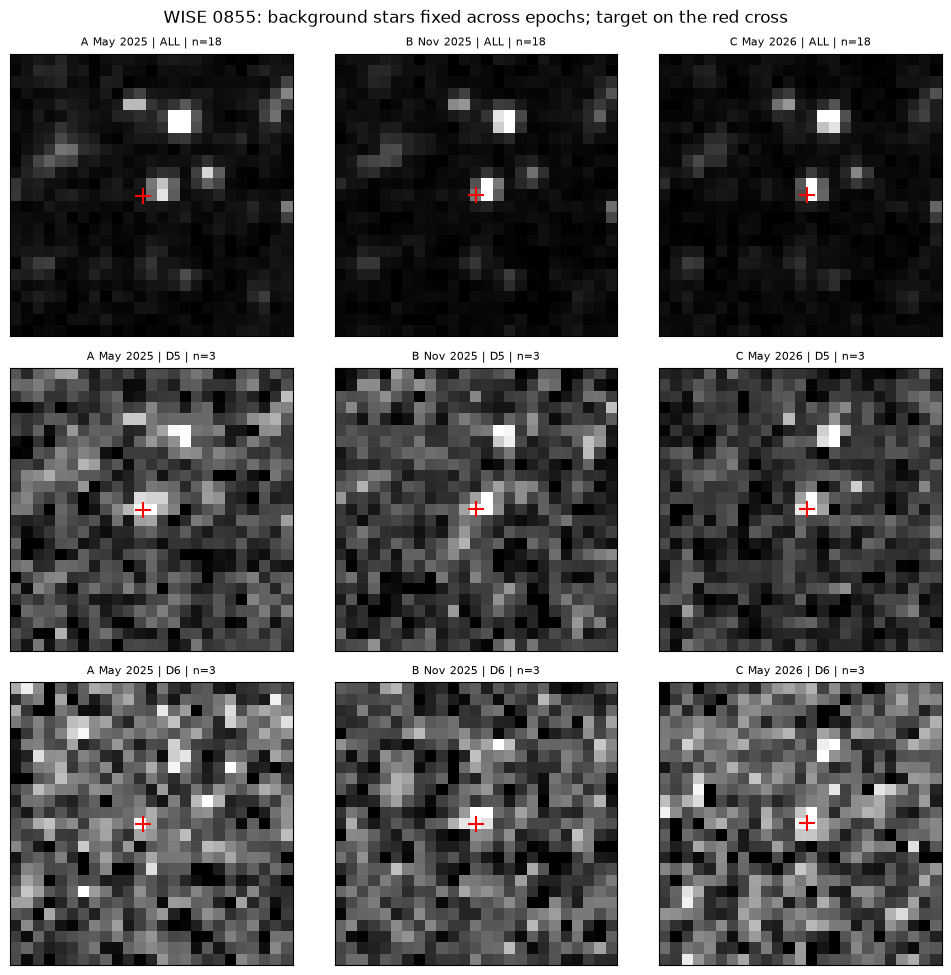

saved /mnt/data/projects/competitions/space-apps/2026/notebooks/test_output/wise0855_epochs.png


In [13]:
# ── 12 · LIVE end-to-end + visual check (saved to test_output/) ──────────────
section("live-e2e", needs=["import:pipeline", "LIVE find_images (WISE 0855)"])

def t_live_build():
    cfg = next(c for c in config.load_targets() if c["id"] == "wise0855")
    d = pipeline.build_target(targets.resolve(cfg), config.load_sources(), config.cache_dir(),
                              max_per_group=3)
    json.dumps(d, allow_nan=False)
    assert len(d["epochs"]) >= 3, f"{len(d['epochs'])} epochs"
    for e in d["epochs"]:
        assert "ALL" in e["frames"], f"epoch {e['id']} has no ALL frame"
    (OUT / "wise0855_live.json").write_text(json.dumps(d))
    print(f"{d['n_used']}/{d['n_images']} cutouts used; saved wise0855_live.json")
    return d

LIVE = check(LIVE_NAMES[3], t_live_build) if RUN_LIVE else skip_all([LIVE_NAMES[3]], "RUN_LIVE = False")

if LIVE:
    import matplotlib.pyplot as plt
    eps, dets = LIVE["epochs"], ["ALL", "D5", "D6"]
    fig, axes = plt.subplots(len(dets), len(eps), figsize=(3.3 * len(eps), 3.3 * len(dets)), squeeze=False)
    for i, det in enumerate(dets):
        for j, e in enumerate(eps):
            ax = axes[i][j]; ax.set_xticks([]); ax.set_yticks([])
            if det not in e["frames"]:
                ax.set_title(f"{e['id']} {det}: none", fontsize=8); continue
            img = np.array(e["frames"][det]["pixels"], dtype=float)
            ax.imshow(img, origin="upper", cmap="gray", interpolation="nearest",
                      vmin=np.nanpercentile(img, 5), vmax=np.nanpercentile(img, 99.5))
            ax.plot(e["predicted_px"]["x"], e["predicted_px"]["y"], "r+", ms=12, mew=1.5)
            ax.set_title(f"{e['id']} {e['label']} | {det} | n={e['frames'][det]['n_images']}", fontsize=8)
    fig.suptitle("WISE 0855: background stars fixed across epochs; target on the red cross")
    plt.tight_layout(); fig.savefig(OUT / "wise0855_epochs.png", dpi=90); plt.show()
    print(f"saved {OUT / 'wise0855_epochs.png'}")

In [ ]:
# ── 13 · blank-pixel reasons on REAL cached cutouts (R Dra saturated, WISE 0855 valid) ──
section("reasons", needs=["import:stack", "import:config", "import:export"])
import glob as _glob

def _cached_near(ra, dec, n=24, tol=0.05):
    """Cached cutouts whose centre is within `tol` deg of (ra, dec); one pass over the headers."""
    out = []
    # config.cache_dir() is py/data/cache by default; full builds have also cached into <repo>/data/cache
    dirs = dict.fromkeys([config.cache_dir(), config.root().parent / "data" / "cache"])
    for p in sorted(p for d in dirs for p in _glob.glob(str(d / "*.fits"))):
        try:
            with fits.open(p) as h:
                img = h["IMAGE"] if "IMAGE" in h else h[1]
                ny, nx = img.data.shape
                cra, cdec = WCS(img.header).celestial.pixel_to_world_values(nx / 2, ny / 2)
        except Exception:
            continue
        if abs(float(cdec) - dec) < tol and abs((float(cra) - ra + 180) % 360 - 180) * np.cos(np.radians(dec)) < tol:
            out.append(p)
        if len(out) >= n:
            break
    return out

def _centre_codes(cfg_id):
    cfg = next(c for c in config.load_targets() if c["id"] == cfg_id)
    t = targets.resolve(cfg)
    s = config.load_sources()
    centre = t.at(float(s["spherex"].get("obs_epoch", 2025.9)))
    paths = _cached_near(centre.ra.deg, centre.dec.deg)
    if not paths:
        raise AssertionError(f"no cached cutouts for {cfg_id}; run `planetx build {cfg_id}` first")
    n = int(s["grid"]["size_px"]); g = stack.make_grid(centre, n, 6.15)
    arrs, bls = zip(*(stack.to_grid_reasons(p, g, n, s["flags"]["bad"], s["flags"]["saturated"]) for p in paths))
    img, _ = stack.stack_epoch(list(arrs))
    why = stack.stack_reasons(img, list(arrs), list(bls))
    c = (n - 1) // 2
    return why.codes[c - 1:c + 2, c - 1:c + 2], len(paths)

def t_rdra_saturated():
    codes, k = _centre_codes("r-dra")
    print(f"R Dra centre 3x3 codes from {k} cached cutouts:\n{codes}")
    assert (codes == stack.SATURATED).all(), f"R Dra centre should be all code 1 (saturated), got\n{codes}"
check("reasons: R Dra centre = 1 (from FLAGS)", t_rdra_saturated,
      "OVERFLOW must be in sources.toml [flags].saturated and checked BEFORE the bad list")

def t_wise_valid():
    codes, k = _centre_codes("wise0855")
    print(f"WISE 0855 centre 3x3 codes from {k} cached cutouts:\n{codes}")
    assert (codes == stack.VALID).all(), f"WISE 0855 centre should be all code 0, got\n{codes}"
check("reasons: WISE 0855 centre = 0", t_wise_valid)

def t_rdra_json():
    d = json.loads((config.web_data_dir() / "targets" / "r-dra.json").read_text())
    for e in d["epochs"]:
        f = e["frames"]["ALL"]
        assert "reasons" in f, f"epoch {e['id']}: no reasons; rebuild with `planetx build r-dra`"
        x, y = round(e["predicted_px"]["x"]), round(e["predicted_px"]["y"])
        got = [f["reasons"][r][x - 1:x + 2] for r in range(y - 1, y + 2)]
        assert all(set(row) == {"1"} for row in got), f"epoch {e['id']} centre reasons {got}"
        assert len(f["reasons"]) == len(f["pixels"]) and all(len(r) == len(f["pixels"][0]) for r in f["reasons"])
        for r, row in enumerate(f["pixels"]):
            for c, v in enumerate(row):
                assert (v is None) == (f["reasons"][r][c] != "0"), f"null/reason mismatch at {r},{c}"
check("reasons: built r-dra.json (centre = 1, aligned with pixels)", t_rdra_json)

def t_reasons_jsonable():
    codes = np.array([[0, 2], [1, 0]], np.uint8); names = np.array([["", "HOT"], ["", ""]], dtype=object)
    out = export.reasons_jsonable(codes, names)
    assert out == {"reasons": ["10", "02"], "flags": {"HOT": 1}}, out   # flipped like to_jsonable
    assert export.reasons_jsonable(np.zeros((2, 2), np.uint8), names) == {}
check("export.reasons_jsonable", t_reasons_jsonable)


In [ ]:
# ── 14 · name lookup (targets.resolve_name, GET /resolve) ─────────────────────────
section("resolve", needs=["import:targets", "import:api", "import:config"])
from fastapi.testclient import TestClient

SESAME_MIRA = """<?xml version="1.0" encoding="UTF-8"?><Sesame><Target option="SNV"><name>Mira</name>
<Resolver name="S=Simbad, IDIA (via url)"><oname>* omi Cet</oname><otype>Mi*</otype>
<jradeg>34.836633758</jradeg><jdedeg>-2.977637673</jdedeg>
<pm><v>237.54</v><pmRA>9.33</pmRA><pmDE>-237.36</pmDE></pm></Resolver></Target></Sesame>"""
SESAME_NONE = """<?xml version="1.0" encoding="UTF-8"?><Sesame><Target option="SNV"><name>zz</name>
<INFO> *** NNNothing found *** </INFO></Target></Sesame>"""

def t_parse_sesame():
    hit = targets.parse_sesame(SESAME_MIRA)
    assert hit["name"] == "* omi Cet" and abs(hit["ra"] - 34.8366) < 1e-3 and abs(hit["dec"] + 2.9776) < 1e-3, hit
    assert hit["pmra"] == 9.33 and hit["pmdec"] == -237.36, hit
    assert targets.parse_sesame(SESAME_NONE) is None, "'Nothing found' must be None, not an error"
check("parse_sesame (hit, pm, not found)", t_parse_sesame)

def t_curated_alias():
    cfgs = config.load_targets()
    for q, want in [("WISE 0855", "wise0855"), ("wise 0855-0714", "wise0855"), ("barnard", "barnard"),
                    ("R Dra", "r-dra"), ("WISE J085510.83-071442.5", "wise0855")]:
        got = targets._curated_match(q, cfgs)
        assert got and got["id"] == want, f"{q!r} -> {got and got['id']}"
    assert targets._curated_match("R", cfgs) is None, "1-3 char prefixes must not match"
    calls = []
    with patched(targets, "sesame", lambda n: calls.append(n)):
        hit = targets.resolve_name("WISE 0855", 2025.9, cfgs)
    assert not calls, "curated alias must not call Sesame"
    # 26 yr of 8.15"/yr: the live query must be centred ~3.5' away from the J2000 position
    moved = SkyCoord(hit["ra"], hit["dec"], unit="deg").separation(
        SkyCoord(hit["ra_epoch"], hit["dec_epoch"], unit="deg")).arcsec
    assert 200 < moved < 220, f"moved {moved:.1f} arcsec"
check("resolve_name: curated alias + proper motion to epoch", t_curated_alias)

def t_api_resolve():
    c = TestClient(api.app)
    with patched(targets, "sesame", lambda n: targets.parse_sesame(SESAME_MIRA if n == "Mira" else SESAME_NONE)):
        r = c.get("/resolve", params={"name": "Mira"})
        assert r.status_code == 200, r.text
        j = r.json()
        assert abs(j["ra_epoch"] - 34.84) < 0.01 and abs(j["dec_epoch"] + 2.98) < 0.01, j
        assert c.get("/resolve", params={"name": "zz"}).status_code == 404
    def down(n):
        raise ConnectionError("all down")
    with patched(targets, "sesame", down):
        assert c.get("/resolve", params={"name": "Mira"}).status_code == 502
    assert c.get("/resolve", params={"name": ""}).status_code == 422
check("GET /resolve (200 / 404 not found / 502 down / 422)", t_api_resolve)

def t_live_sesame():
    hit = targets.resolve_name("Mira", 2025.9, [])
    print(f"Mira -> {hit['name']}: {hit['ra_epoch']:.4f}, {hit['dec_epoch']:+.4f} via {hit['source']}")
    assert abs(hit["ra_epoch"] - 34.84) < 0.01 and abs(hit["dec_epoch"] + 2.98) < 0.01, hit
    assert targets.resolve_name("zzzznotanobject", 2025.9, []) is None
if RUN_LIVE:
    check("LIVE Sesame (Mira, not found)", t_live_sesame, "both Sesame servers down?")
else:
    skip_all(["LIVE Sesame (Mira, not found)"], "RUN_LIVE = False")


In [ ]:
# ── 15 · motion.py: measured vs predicted shift (centroid estimate) ─────────────────
section("motion", needs=["import:config"])
motion = importlib.import_module("planetx.motion")

def _synthetic(shift_x=1.5, pred_x=None, amp=50.0, sat=False, n=25, seed=0, star_b=None):
    """Two epochs, Gaussian star (sigma 0.8 px) at x = 12 then 12 + shift_x; noise sigma 1.
    pred_x: predicted shift (default = shift_x). star_b: put epoch B's star at this x instead
    (a different object)."""
    rng = np.random.default_rng(seed)
    pred_x = shift_x if pred_x is None else pred_x
    eps = []
    for k, (dx, pdx) in enumerate([(0.0, 0.0), (shift_x, pred_x)]):
        sx = star_b if (k == 1 and star_b is not None) else 12 + dx
        yy, xx = np.mgrid[:n, :n]
        img = rng.normal(0, 1, (n, n)) + amp * np.exp(-((xx - sx) ** 2 + (yy - 12) ** 2) / (2 * 0.8 ** 2))
        px = img.tolist(); reasons = None
        if sat:
            c = round(sx); px[12][c] = None
            reasons = ["0" * n] * n; reasons[12] = "0" * c + "1" + "0" * (n - c - 1)
        f = {"pixels": px, **({"reasons": reasons} if reasons else {})}
        eps.append({"id": "AB"[k], "predicted_px": {"x": 12 + pdx, "y": 12.0}, "frames": {"D6": f}})
    return {"epochs": eps}

def t_motion_synthetic():
    m = motion.measure_motion(_synthetic(1.5))
    assert m["measurable"] and m["detector"] == "D6" and abs(m["predicted_px"] - 1.5) < 1e-9, m
    assert abs(m["measured_px"] - 1.5) < 0.2, m
    # the bias this method removes: a STATIONARY star with a predicted shift must not "move"
    s = motion.measure_motion(_synthetic(0.0, pred_x=1.5))
    assert s["measurable"] and s["measured_px"] < 0.15, s
    print(f"mover 1.5 px -> {m['measured_px']:.3f} px; stationary star, 1.5 px predicted -> {s['measured_px']:.3f} px")
check("motion: synthetic mover + stationary star with a predicted shift", t_motion_synthetic)

def t_motion_reasons():
    assert motion.measure_motion(_synthetic(1.0, sat=True))["reason"] == "saturated"
    assert motion.measure_motion(_synthetic(1.0, amp=1.0))["reason"] == "faint"
    amb = motion.measure_motion(_synthetic(1.0, star_b=16.0, amp=80.0))   # peak jumps 4 px, 1 predicted
    assert amb["reason"] == "ambiguous" and amb["measured_px"] is None, amb
    one = _synthetic(); one["epochs"] = one["epochs"][:1]
    assert motion.measure_motion(one) is None, "one epoch -> no motion"
check("motion: saturated / faint / ambiguous / single epoch", t_motion_reasons)

def _built(tid):
    d = json.loads((config.web_data_dir() / "targets" / f"{tid}.json").read_text())
    stored = d.pop("motion", None)
    return d, stored

def t_motion_null():
    d, stored = _built("wise0855")
    nt = motion.null_test(d)
    assert nt is not None, "no reference star found in the WISE 0855 field"
    print(f"reference star at pixel x {nt['x']}, y {nt['y']} ({nt['detector']}): {nt['measured_px']} px")
    assert nt["measurable"] and nt["measured_px"] < 0.3, nt
    assert stored and stored.get("null_test") == nt, "stored motion.null_test is stale: run `planetx annotate`"
check("motion: null test, stationary star in the WISE 0855 field < 0.3 px", t_motion_null)

def t_motion_wise():
    d, stored = _built("wise0855")
    m = motion.measure_motion(d)
    print(f"WISE 0855: measured {m['measured_px']:.3f} px vs {m['predicted_px']:.3f} px predicted in {m['detector']}")
    assert m["measurable"] and abs(m["measured_px"] - m["predicted_px"]) <= 0.5, m
    assert stored == m, "stored `motion` is stale: run `planetx annotate`"
check("motion: WISE 0855 measurable, within 0.5 px of predicted", t_motion_wise)

def t_motion_rdra():
    d, stored = _built("r-dra")
    m = motion.measure_motion(d)
    assert not m["measurable"] and m["reason"] == "saturated" and m["measured_px"] is None, m
    assert stored == m, "stored `motion` is stale: run `planetx annotate`"
check("motion: R Dra not measurable (saturated)", t_motion_rdra)

def _old_method(data):
    """The previous method, kept here only for comparison: 3x3 window centred on each epoch's
    PREDICTED position, reddest detector with S/N >= 3 in every epoch."""
    eps = data["epochs"]
    for det in motion.DETECTOR_ORDER:
        if not all(det in e["frames"] for e in eps):
            continue
        cs = []
        for e in eps:
            img = motion._image(e["frames"][det]); bg, noise = motion._stats(img)
            cx, cy = round(e["predicted_px"]["x"]), round(e["predicted_px"]["y"])
            win = img[cy - 1:cy + 2, cx - 1:cx + 2]
            if win.shape != (3, 3) or np.isnan(win).any() or (win.max() - bg) / noise < 3:
                break
            w = np.clip(win - bg, 0, None); yy, xx = np.mgrid[cy - 1:cy + 2, cx - 1:cx + 2]
            cs.append(((w * xx).sum() / w.sum(), (w * yy).sum() / w.sum()))
        if len(cs) == len(eps):
            return float(np.hypot(cs[-1][0] - cs[0][0], cs[-1][1] - cs[0][1])), det
    return None, None

def t_motion_old_vs_new():
    import copy
    d, _ = _built("wise0855")
    new, nt = motion.measure_motion(d), motion.null_test(d)
    star = copy.deepcopy(d)
    for e in star["epochs"]:
        e["predicted_px"] = {"x": nt["x"], "y": nt["y"]}
    rows = [("WISE 0855", new["predicted_px"], _old_method(d), (new["measured_px"], new["detector"])),
            (f"null star ({nt['x']},{nt['y']})", 0.0, _old_method(star), (nt["measured_px"], nt["detector"]))]
    print(f"{'':22s}{'predicted':>10s}{'old 3x3@pred':>16s}{'new 5x5@peak':>16s}")
    for name, pred, (o, od), (n_, nd) in rows:
        print(f"{name:22s}{pred:>10.3f}{(f'{o:.3f} ' + od) if o is not None else 'n/a':>16s}{f'{n_:.3f} {nd}':>16s}")
check("motion: old vs new (WISE 0855, null star)", t_motion_old_vs_new, needs=["motion: null test, stationary star in the WISE 0855 field < 0.3 px"])


In [ ]:
# ── 16 · spectral.py: per-pixel wavelength from the spectral WCS (WAVE-TAB) ────────
section("spectral", needs=["import:config", "import:stack"])
import re as _re
spectral = importlib.import_module("planetx.spectral")

def _tab_header(crpix=1.0):
    h = fits.Header()
    for i, ax in ((1, "X"), (2, "Y")):
        h[f"CTYPE{i}W"] = "WAVE-TAB"; h[f"CUNIT{i}W"] = "um"; h[f"CRPIX{i}W"] = crpix
        h[f"CRVAL{i}W"] = 1; h[f"CDELT{i}W"] = 1; h[f"PS{i}_0W"] = "WCS-WAVE"; h[f"PS{i}_1W"] = "VALUES"
        h[f"PS{i}_2W"] = ax; h[f"PV{i}_3W"] = i
    return h

def _tab(kx=(1, 300, 1000, 2040), ky=(1, 1000, 2040)):
    """lambda = 1 + 0.001 * X + 0.0005 * Y, bandwidth = 0.01 * lambda: bilinear is then exact,
    even with UNEVEN control points."""
    X, Y = np.array(kx, float), np.array(ky, float)
    lam = 1 + 0.001 * X[None, :] + 0.0005 * Y[:, None]
    return spectral.WaveTable(X, Y, np.stack([lam, 0.01 * lam], axis=-1))

def t_tab_synthetic():
    t = _tab()
    lam, bw = spectral.wavelength_at(_tab_header(1.0), t, np.array([0, 499, 2039]), np.array([0, 9, 2039]))
    want = 1 + 0.001 * np.array([1, 500, 2040]) + 0.0005 * np.array([1, 10, 2040])   # p = x + 1
    assert np.allclose(lam, want, atol=1e-12) and np.allclose(bw, 0.01 * want), (lam, want)
    # IRSA cutout with CRPIX = -1227: psi = 1 + (1 - (-1227)) = 1229, i.e. cutout pixel 1 is
    # raw detector pixel 1229 (the cutout starts at 0-based raw column/row 1228)
    lam2, _ = spectral.wavelength_at(_tab_header(-1227.0), t, 0, 0)
    assert abs(lam2 - (1 + 0.001 * 1229 + 0.0005 * 1229)) < 1e-12, lam2
    out, _ = spectral.wavelength_at(_tab_header(1.0), t, np.array([-1.0, 2040.0]), np.array([5.0, 5.0]))
    assert np.isnan(out).all(), f"outside the control points must be NaN, got {out}"
    h = _tab_header(); h["PC1_2W"] = 0.1
    try:
        spectral.wavelength_at(h, t, 0, 0); raise AssertionError("PC matrix must be rejected")
    except ValueError:
        pass
check("wavelength_at: synthetic WAVE-TAB (uneven control points, cutout CRPIX, range, PC)", t_tab_synthetic)

def _wise_cutouts(n=24):
    cfg = next(c for c in config.load_targets() if c["id"] == "wise0855")
    centre = targets.resolve(cfg).at(2025.9)
    return _cached_near(centre.ra.deg, centre.dec.deg, n=n), centre

def t_tab_vs_wcslib():
    paths, _ = _wise_cutouts(12)
    assert paths, "no cached WISE 0855 cutouts; run `planetx build wise0855` first"
    worst = 0.0
    for p in paths:
        with fits.open(p) as h:
            hd = h["IMAGE"].header
            t = spectral.read_wave_table(h["WCS-WAVE"], hd)
            ny, nx = h["IMAGE"].data.shape
            yy, xx = np.mgrid[:ny, :nx]
            lam, bw = spectral.wavelength_at(hd, t, xx, yy)
            nosip = hd.copy()   # SIP corrects pixel -> SKY; the table is in raw detector pixels
            for k in [k for k in nosip if _re.fullmatch(r"(A|B|AP|BP)_(\d+_\d+|ORDER|DMAX)", k)]:
                del nosip[k]
            with warnings.catch_warnings():
                warnings.simplefilter("ignore")
                ref = WCS(nosip, fobj=h, key="W").pixel_to_world_values(xx, yy)
            worst = max(worst, float(np.nanmax(np.abs(lam - ref[0]))), float(np.nanmax(np.abs(bw - ref[1]))))
    print(f"{len(paths)} cutouts: max |wavelength_at - wcslib| = {worst:.1e} um")
    assert worst < 1e-9, worst
check("wavelength_at == wcslib -TAB on real cutouts", t_tab_vs_wcslib)

def t_wise_wavelengths():
    """The brief's check: for a known source, wavelengths fall within 0.75-5.0 um and
    increase with detector number. Every cached WISE 0855 cutout, at the target's position.
    Tolerance 0.01 um (less than one channel's bandwidth, 0.018-0.038 um): the filters reach
    slightly past the nominal range. IRSA's own SIA band for these exposures is 0.746-5.01 um,
    and WISE 0855 has samples at 0.744 and 5.003 um. Edge samples are printed."""
    paths, centre = _wise_cutouts(400)
    by_det = {}
    for p in paths:
        with fits.open(p) as h:
            hd = h["IMAGE"].header
            x, y = WCS(hd).celestial.world_to_pixel(centre)
            lam, _ = spectral.wavelength_at(hd, spectral.read_wave_table(h["WCS-WAVE"], hd), x, y)
            by_det.setdefault(int(hd["DETECTOR"]), []).append(float(lam))
    assert sorted(by_det) == [1, 2, 3, 4, 5, 6], f"detectors {sorted(by_det)}"
    allw = np.concatenate([np.array(v) for v in by_det.values()])
    TOL = 0.01
    assert np.isfinite(allw).all() and 0.75 - TOL <= allw.min() and allw.max() <= 5.0 + TOL, (allw.min(), allw.max())
    edge = sorted(float(w) for w in allw if w < 0.75 or w > 5.0)
    print(f"outside nominal 0.75-5.0 um (within {TOL} um tolerance): {[round(w, 4) for w in edge]}")
    meds = [np.median(by_det[d]) for d in range(1, 7)]
    assert all(np.diff(meds) > 0), f"medians not increasing: {meds}"
    for d in range(1, 6):   # no overlap beyond the dichroic crossover: D(n) max < D(n+1) max
        assert max(by_det[d]) < max(by_det[d + 1]), d
    print(f"{len(allw)} cutouts, {allw.min():.3f}-{allw.max():.3f} um; median per D1..D6: "
          + ", ".join(f"{m:.2f}" for m in meds))
check("WISE 0855 wavelengths in 0.75-5.0 um, increasing with detector", t_wise_wavelengths)

def t_sidecar():
    tdir = config.web_data_dir() / "targets"
    d = json.loads((tdir / "wise0855.json").read_text())
    sp = json.loads((tdir / "wise0855.spectrum.json").read_text())
    n, c = sp["size_px"], sp["wave_origin_px"]
    assert len(sp["exposures"]) >= 0.95 * d["n_used"], (len(sp["exposures"]), d["n_used"])
    ranges = d["detectors"]
    for e in sp["exposures"]:
        assert len(e["pixels"]) == n and len(e["pixels"][0]) == n
        for col, row in ((0, 0), (n - 1, n - 1), (12, 12)):
            lam = e["wave"][0] + e["wave"][1] * (col - c) + e["wave"][2] * (row - c)
            lo, hi = ranges[e["detector"]]
            assert lo - 0.01 <= lam <= hi + 0.01, f"{e['obs_id']} {e['detector']}: {lam:.3f} outside SIA band {lo}-{hi}"
check("spectrum sidecar (wise0855): every exposure's wavelength inside its SIA band", t_sidecar)

def t_refine_exposures():
    cache = TMP / "apispec"; cache.mkdir(exist_ok=True)
    def with_wave(client, url, plan, grid, bad, margin, deadline):
        f = fake_frame(client, url, plan, grid, bad, margin, deadline)
        return f, {"wave": [4.5, 0.0, 0.001], "bandwidth": 0.04}
    with fake_archive(cache), patched(live, "_fetch_frame", with_wave):
        c = TestClient(api.app)
        plan = c.get("/target", params={"ra": 133.7951, "dec": -7.2451}).json()
        d = c.post("/target/refine", json={"ra": 133.7951, "dec": -7.2451, "cursor": plan["refine"]["cursor"],
                                           "batch_per_epoch": 2}).json()
    a, b = d["epochs"]
    assert [x["detector"] for x in a["exposures"]] == ["D6", "D5"], a["exposures"]
    assert a["exposures"][0]["wave"] == [4.5, 0.0, 0.001] and a["exposures"][0]["pixels"][24][0] is None
    assert b["exposures"] == [], "failed / all-masked exposures carry no samples"
check("refine returns per-exposure samples with wavelength", t_refine_exposures, needs=["import:api"])

def t_live_wave_window():
    remote_ = importlib.import_module("planetx.remote")
    import httpx
    url = str(LIVE_IMAGES["access_url"][0])
    g = stack.make_grid(WISE, 25, 6.15)
    with httpx.Client(follow_redirects=True) as cl:
        data, wcs, spec = remote_.read_window(cl, url, WISE, 19, time.monotonic() + 60, ["HOT"],
                                              subtract_zodi=False, wave=True)
    a = spectral.grid_wavelength(spec[0], spec[1], wcs, g, 25)
    p = cutouts.fetch_cutout(cutouts.cutout_url(url, WISE, 0.064), config.cache_dir())
    b = spectral.exposure_wavelength(p, g, 25)
    print(f"range read {a['wave']}  cutout service {b['wave']}")
    assert np.allclose(a["wave"], b["wave"], atol=1e-5), (a, b)
if RUN_LIVE:
    check("LIVE wavelength: range-read window == IRSA cutout", t_live_wave_window, needs=["LIVE find_images (WISE 0855)"])
else:
    skip_all(["LIVE wavelength: range-read window == IRSA cutout"], "RUN_LIVE = False")


## Report
Summary by section, then each failure with message, hint, traceback and output.

In [14]:
# ── 13 · Report ───────────────────────────────────────────────────────────────
from collections import Counter, defaultdict

total = len(RESULTS)
counts = Counter(r["status"] for r in RESULTS.values())
by_section = defaultdict(Counter)
for r in RESULTS.values():
    by_section[r["section"]][r["status"]] += 1

cols = ["pass", "fail", "crash", "todo", "skip"]
W = 78
lines = ["PLANETX TEST REPORT", f"Generated {datetime.now():%Y-%m-%d %H:%M}   Live checks: {'on' if RUN_LIVE else 'off'}",
         "=" * W, "",
         f"{'Section':<14}" + "".join(f"{LABEL[c]:>7}" for c in cols) + f"{'Total':>7}",
         "-" * (14 + 7 * (len(cols) + 1))]
for sec, c in by_section.items():
    lines.append(f"{sec:<14}" + "".join(f"{c[k]:>7}" for k in cols) + f"{sum(c.values()):>7}")
lines += ["-" * (14 + 7 * (len(cols) + 1)),
          f"{'TOTAL':<14}" + "".join(f"{counts[k]:>7}" for k in cols) + f"{total:>7}", ""]

problems = {n: r for n, r in RESULTS.items() if r["status"] in ("fail", "crash")}
todos = [n for n, r in RESULTS.items() if r["status"] == "todo"]
skips = {n: r for n, r in RESULTS.items() if r["status"] == "skip"}

if problems:
    lines += ["=" * W, f"FAILURES AND ERRORS ({len(problems)}) — in run order", "=" * W]
    for i, (n, r) in enumerate(problems.items(), 1):
        lines += ["", f"{i}. [{LABEL[r['status']]}] {n}",
                  f"   Section : {r['section']}",
                  f"   Message : {r['message']}"]
        if r["hint"]:
            lines.append(f"   Hint    : {r['hint']}")
        tb = [l for l in r["traceback"].strip().splitlines() if l.strip()]
        if tb:
            lines.append("   Trace   :")
            lines += ["      " + l for l in tb[-8:]]
        if r["output"].strip():
            lines.append("   Output  :")
            lines += ["      " + l for l in r["output"].strip().splitlines()[-6:]]
        lines.append(f"   Time    : {r['seconds']}s")
    lines.append("")
if todos:
    lines += ["-" * W, f"NOT IMPLEMENTED ({len(todos)})", "-" * W] + [f"   {n}" for n in todos] + [""]
if skips:
    lines += ["-" * W, f"SKIPPED ({len(skips)})", "-" * W] + [f"   {n}  ({r['message']})" for n, r in skips.items()] + [""]

slow = sorted(((r["seconds"], n) for n, r in RESULTS.items() if r["seconds"] > 5), reverse=True)
if slow:
    lines += ["Slowest checks:"] + [f"   {s:6.1f}s  {n}" for s, n in slow[:5]] + [""]

lines.append("=" * W)
offline_ok = not problems and not todos and all(r["status"] == "pass" or n.startswith("LIVE ") for n, r in RESULTS.items())
if total and counts["pass"] == total:
    lines += ["RESULT: ALL GOOD — all checks passed.",
              "Final manual step: confirm the epoch plot (test_output/wise0855_epochs.png)."]
elif offline_ok and not RUN_LIVE:
    lines += ["RESULT: OFFLINE CHECKS PASSED — live checks skipped. Set RUN_LIVE = True and re-run."]
else:
    lines += [f"RESULT: INCOMPLETE — {len(problems)} failing, {len(todos)} not implemented, {len(skips)} skipped."]
lines.append("=" * W)

report = "\n".join(lines)
print(report)
(OUT / "report.md").write_text("```\n" + report + "\n```\n")
_save()
print(f"\nSaved: {OUT / 'report.md'}\n       {RESULTS_FILE}")

PLANETX TEST REPORT
Generated 2026-11-14 09:51   Live checks: on

Section          PASS   FAIL  ERROR   TODO   SKIP  Total
--------------------------------------------------------
imports             9      0      0      0      0      9
config              5      0      0      0      0      5
targets             8      0      0      0      0      8
query               8      0      0      0      0      8
cutouts             8      0      0      0      0      8
stack               8      0      0      0      0      8
export              2      0      0      0      0      2
pipeline            5      0      0      0      0      5
cli                 2      0      0      0      0      2
api                 4      0      0      0      0      4
live                3      0      0      0      0      3
live-e2e            1      0      0      0      0      1
--------------------------------------------------------
TOTAL              63      0      0      0      0     63

Slowest checks:
     